# EDA для **Кредитного скоринга** 
## Горюнов ВА . 

In [2]:
import pandas as pd
df_train = pd.read_csv('shift_ml_2026_train.csv') # занесем датасет во фрейм
df_test = pd.read_csv('shift_ml_2026_test.csv')

print("Train data shape:", df_train.shape)
print("Test data shape: ", df_test.shape)

C:\Users\narut\AppData\Local\Temp\ipykernel_12080\1958410103.py:2: DtypeWarning: Columns (49) have mixed types. Specify dtype option on import or set low_memory=False.
  df_train = pd.read_csv('shift_ml_2026_train.csv') # занесем датасет во фрейм


Train data shape: (1210779, 109)
Test data shape:  (134531, 108)


In [ ]:
from ydata_profiling import ProfileReport #попытка сделать отчет с помощью бибилотеки яндекса
print(df_train.sample(30)) # случайные записи
print(df_test.head(5))  # 
print(df_test.tail(5))
print(df_train.isnull().sum())
if not df_train[df_train.duplicated(keep=False)].empty:
    print("Дубликатs есть") # проверка на дубликаты
else:
    print("Дубликатов нет")
profile = ProfileReport(df_train, title="Dashboard")
display(profile)

                id  сумма_займа срок_займа  процентная_ставка  аннуитет рейтинг допрейтинг                               профессия_заемщика      стаж владение_жильем  годовой_доход  подтвержден_ли_доход  итоговый_статус_займа  рейтинг_OCR платежный_график  коэфф_акционных_зачислений_в_остатке                  цель_займа  кол_во_субсидий_за_год  индекс_проживания                             регион    пдн пос_стоп_фактор юридический_статус  кол-во_просрочек_за_два_года  коэфф_невыплаченного_сумм_остатка  коэфф_исходного_платежа дата_первого_займа  нижний_порог_рейтинга_заемщика  верхний_порог_рейтинга_заемщика  кол-во_заявок_за_полгода  кол-во_месяцев_с_последней_просрочки  кол-во_месяцев_с_последнего_займа  кол-во_открытых_счетов  кол-во_записей_в_общедоступных_документах  оборотный_баланс  коэфф_загрузки_возобновляемого_счета  кол-во_счетов первоначальный_статус_займа  непогашенная_сумма_из_тела_займов  сумма_выплат_по_просрочкам пени_за_дефолт  дата_следующей_выплаты  грейд_на_детерми

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 109/109 [00:53<00:00,  2.03it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [3]:
print(set(df_train.columns)-set(df_test.columns)) # выделяем различия в столбца в train и test

{'итоговый_статус_займа'}


In [4]:
print(df_train.head(2).T) # смотрим пример записей и анализируем как закодировать категориальные

                                          0          1
id                                 68355089   68341763
сумма_займа                       1235000.0  1000000.0
срок_займа                           3 года      5 лет
процентная_ставка                     11.99      10.78
аннуитет                            41014.0    21633.0
...                                     ...        ...
лимит_по_картам                   3965000.0   310000.0
лимит_по_аннуитетным_счетам       1233350.0   743850.0
кредитный_баланс_по_возоб_счетам        NaN        NaN
особая_ситуация                         Нет        Нет
тип_предоставления_кредита         Наличные   Наличные

[109 rows x 2 columns]


In [5]:
for column in df_train.columns: # выдаем все уникльыне значения в каждом столбце
    unique_vals = df_train[column].unique()
    print(f"\n{column}:")
    print(f"  Всего уникальных: {len(unique_vals)}")
    print(f"  Значения: {unique_vals[:]}")


id:
  Всего уникальных: 1210779
  Значения: [68355089 68341763 68426831 ... 89996426 90006534 88224441]

сумма_займа:
  Всего уникальных: 1551
  Значения: [1235000. 1000000.  597500. ... 1817500. 1872500. 1836250.]

срок_займа:
  Всего уникальных: 2
  Значения: ['3 года' '5 лет']

процентная_ставка:
  Всего уникальных: 650
  Значения: [11.99 10.78 13.44  9.17  8.49  6.49 11.48 12.88 19.48  7.49 19.89 14.85
  5.32 17.97 24.24 13.99 15.77  9.8  17.27 18.49  7.91 23.13 16.59 20.5
 18.99 26.06 22.45 21.48  6.99 27.49 26.99 27.99 28.49 25.09  6.   28.99
 16.55 13.67 17.86 14.48 10.64 13.18  6.24  7.26  8.38 15.41  9.76 21.99
 16.99 25.99 12.59 17.57  7.89  6.89 18.2  11.22 19.99 27.31 20.99 27.88
 23.99 22.99 24.99 26.77  8.18  9.99 11.49 10.99 14.33 12.05 16.9  11.53
 18.55 14.65 13.33 12.69 18.25 19.19 12.29 15.61 25.78 19.52  6.39  5.93
  6.92  6.68 21.67 20.49 25.8  18.84 24.5  25.57 25.83 25.89  8.67 14.99
 17.14  8.19 10.49 11.44  6.03 12.39  9.49 13.66 14.31 12.99 15.99 15.59
 19.24

In [6]:
df_train['срок_займа'] = df_train['срок_займа'].str.extract('(\d+)').astype(int) # оставляем только число
df_test['срок_займа'] = df_test['срок_займа'].str.extract('(\d+)').astype(int)

rating_order = {'А': 7, 'Б': 6, 'В': 5, 'Г': 4, 'Д': 3, 'Е': 2, 'Ж': 1} # кодируем по уровню престижа: чем меньше буква по алфавиту, тем лучеш
df_train['рейтинг'] = df_train['рейтинг'].map(rating_order)
df_test['рейтинг'] = df_test['рейтинг'].map(rating_order)

rating_map = {
    
    'Ж5': 1,   
    'Ж4': 2,
    'Ж3': 3,
    'Ж2': 4,
    'Ж1': 5,   
    'Е5': 6,
    'Е4': 7,
    'Е3': 8,
    'Е2': 9,
    'Е1': 10,
    'Д5': 11,
    'Д4': 12,
    'Д3': 13,
    'Д2': 14,
    'Д1': 15,
    'Г5': 16,
    'Г4': 17,
    'Г3': 18,
    'Г2': 19,
    'Г1': 20,
    'В5': 21,
    'В4': 22,
    'В3': 23,
    'В2': 24,
    'В1': 25,
    'Б5': 26,
    'Б4': 27,
    'Б3': 28,
    'Б2': 29,
    'Б1': 30,
    'А5': 31,
    'А4': 32,
    'А3': 33,
    'А2': 34,
    'А1': 35    
}
df_train['допрейтинг'] = df_train['допрейтинг'].map(rating_map) # кодируем по уровню престижа: чем меньше буква по алфавиту и большое число, тем лучеш
df_test['допрейтинг'] = df_test['допрейтинг'].map(rating_map)

df_train['стаж'] = df_train['стаж'].replace({ # оставляем только число
    '10+ лет': 10.0,
    '< 1 года': 0.5,
    '1 год': 1.0
}).str.extract(r'(\d+)').astype(float)
df_test['стаж'] = df_test['стаж'].replace({
    '10+ лет': 10.0,
    '< 1 года': 0.5,
    '1 год': 1.0
}).str.extract(r'(\d+)').astype(float)

dummies = pd.get_dummies(df_train['владение_жильем'], prefix='жилье') # one hot encoding для владения жилья
dummies = dummies.iloc[:, 1:] 
df_train = pd.concat([df_train, dummies], axis=1)
df_train = df_train.drop('владение_жильем', axis=1)

dummies = pd.get_dummies(df_test['владение_жильем'], prefix='жилье')
dummies = dummies.iloc[:, 1:] 
df_test = pd.concat([df_test, dummies], axis=1)
df_test = df_test.drop('владение_жильем', axis=1)

def encode_purpose_groups(df, purpose_col='цель_займа'): # делим цели на группы, а другы по one hot encoding
    
    purpose_groups = {
        'инвестиции_в_активы': [
            'улучшение_жилищных_условий', 'дом', 'автомобиль', 'крупная_покупка'
        ],
        'образование_здоровье': [
            'образование', 'лечение', 'отпуск'  
        ],
        'бизнес': [
            'мелкий_бизнес', 'возобновляемая_энергия'
        ],
        'долги_рефинансирование': [
            'консолидация_долга', 'кредитная_карта'
        ],
        'жизненные_события': [
            'свадьба', 'переезд'
        ],
        'другое': [
            'другое'
        ]
    }
    
    group_mapping = {}
    for group, purposes in purpose_groups.items():
        for purpose in purposes:
            group_mapping[purpose] = group
    
    df[f'{purpose_col}_group'] = df[purpose_col].map(group_mapping)
    
    dummies = pd.get_dummies(df[f'{purpose_col}_group'], prefix='цель')
    df = pd.concat([df, dummies], axis=1)
    df= df.drop('цель_займа', axis=1)
    df= df.drop('цель_займа_group', axis=1)
    return df
df_train=encode_purpose_groups(df_train)
df_test=encode_purpose_groups(df_test)

df_train['дата_первого_займа'] = ( # преводим в количество недель до сегодня
    (pd.Timestamp.now().year - df_train['дата_первого_займа'].str.split('-').str[1].astype(int)) * 12 +
    (pd.Timestamp.now().month - df_train['дата_первого_займа'].str.split('-').str[0].astype(int))
)
df_test['дата_первого_займа'] = (
    (pd.Timestamp.now().year - df_test['дата_первого_займа'].str.split('-').str[1].astype(int)) * 12 +
    (pd.Timestamp.now().month - df_test['дата_первого_займа'].str.split('-').str[0].astype(int))
)
# считаем, что перевод лучше, чем наличные
df_train['тип_предоставления_кредита'] = (df_train['тип_предоставления_кредита'] == 'наличные').astype(int)
df_test['тип_предоставления_кредита'] = (df_test['тип_предоставления_кредита'] == 'наличные').astype(int)
# платежный график это рудимент, там только одно значение возможно
df_train = df_train.drop('платежный_график', axis=1)
df_test= df_test.drop('платежный_график', axis=1)
# удалим, там как большого смысла не нашлось
df_train = df_train.drop('первоначальный_статус_займа', axis=1)
df_test= df_test.drop('первоначальный_статус_займа', axis=1)
# удалим, там как большого смысла не нашлось
df_train = df_train.drop('особая_ситуация', axis=1)
df_test= df_test.drop('особая_ситуация', axis=1)

income_verification_map = { # лучше, если доход подтвержден
    'Не подтвержден': 0,      # худший вариант
    'Подтвержден источник': 1, # средний
    'Подтвержден': 2           # лучший
}

df_train['подтвержден_ли_доход'] = df_train['подтвержден_ли_доход'].map(income_verification_map)
df_test['подтвержден_ли_доход'] = df_test['подтвержден_ли_доход'].map(income_verification_map)
 # лучше, если проблемы сразу невидны
stop_factor_map = {
    'Нет': 0,           # нет проблем
    'Под вопросом': 1,  # потенциальные проблемы
    'Да': 2             # есть проблемы
}

df_train['пос_стоп_фактор'] = df_train['пос_стоп_фактор'].map(income_verification_map)
df_test['пос_стоп_фактор'] = df_test['пос_стоп_фактор'].map(income_verification_map)
 # лучше, если юр статус есть
status_map = {'Нет': 0, 'Да': 1}
df_train['юридический_статус'] = df_train['юридический_статус'].map(income_verification_map)
df_test['юридический_статус'] = df_test['юридический_статус'].map(income_verification_map)
# one hot encoding для регионов
def encode_regions_target_and_drop(df, region_col='регион', target_col='итоговый_статус_займа'):
    region_means = df.groupby(region_col)[target_col].mean()
    df['регион'] = df[region_col].map(region_means)
    df['регион'] = df['регион'].fillna(df[target_col].mean())
    return df, region_means.to_dict()

df_train, region_risk_map = encode_regions_target_and_drop(df_train)
df_test['регион'] = df_test['регион'].map(region_risk_map)
 # лучше, если нет пени
df_train['пени_за_дефолт'] = df_train['пени_за_дефолт'].astype(float)
df_test['пени_за_дефолт'] = df_test['пени_за_дефолт'].astype(float)
 # лучше, совместный платеж, он более подстрахован от неуплаты
df_train['тип_займа'] = (df_train['тип_займа'] == 'Совместный').astype(int)
df_test['тип_займа'] = (df_test['тип_займа'] == 'Совместный').astype(int)

income_verification_map = {
    'Не подтвержден': 0,
    'Подтвержден источник': 1,
    'Подтвержден': 2
}
 # лучше, если доходы подтверждены
df_train['совокупный_статус_подтверждения_доходов_заемщиков'] = df_train['совокупный_статус_подтверждения_доходов_заемщиков'].map(income_verification_map)
df_test['совокупный_статус_подтверждения_доходов_заемщиков'] = df_test['совокупный_статус_подтверждения_доходов_заемщиков'].map(income_verification_map)
 # сложный параметр, просто удалил его. количество профессия почти такого же порядка как и датасет
df_train = df_train.drop('профессия_заемщика', axis=1, errors='ignore')
df_test = df_test.drop('профессия_заемщика', axis=1, errors='ignore')
total_rows = len(df_train)
missing_percent = (df_train.isnull().sum() / total_rows * 100).sort_values(ascending=False)
threshold = 50  
columns_to_drop = missing_percent[missing_percent > threshold].index.tolist()
df_train = df_train.drop(columns=columns_to_drop)
df_test = df_test.drop(columns=columns_to_drop)
train_medians = df_train.median(numeric_only=True)
df_train = df_train.fillna(train_medians)
df_test = df_test.fillna(train_medians)
print("Нет пропусков" if df_train.isnull().sum().sum()+df_test.isnull().sum().sum()==0 else "Есть пропуски")

Нет пропусков


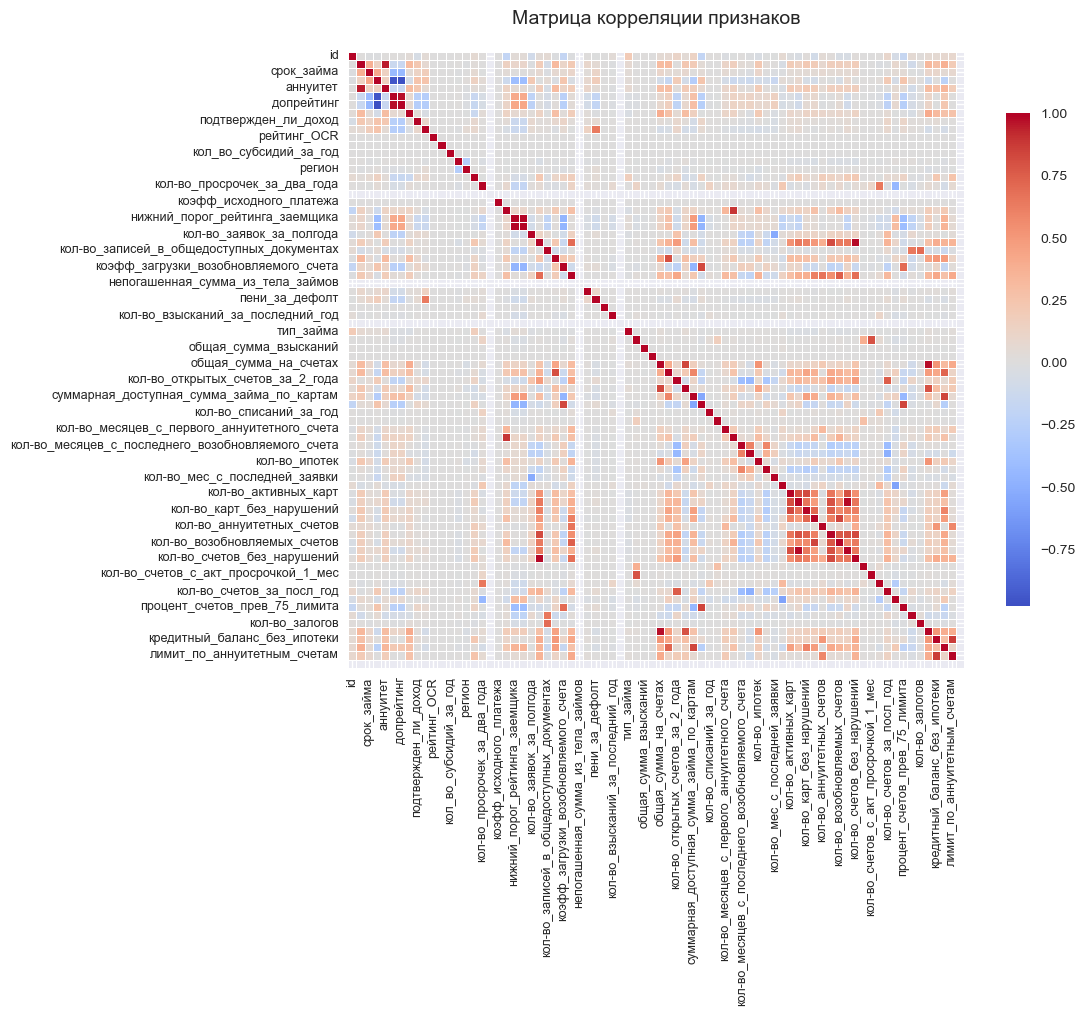

Сильно коррелированные пары признаков (|корреляция| > 0.7):
  сумма_займа - аннуитет: 0.953
  процентная_ставка - рейтинг: -0.953
  процентная_ставка - допрейтинг: -0.977
  рейтинг - допрейтинг: 0.976
  дата_первого_займа - кол-во_месяцев_с_первого_возобновляемого_счета: 0.885
  нижний_порог_рейтинга_заемщика - верхний_порог_рейтинга_заемщика: 1.000
  кол-во_открытых_счетов - кол-во_счетов: 0.702
  кол-во_открытых_счетов - кол-во_открытых_возобновляемых_счетов: 0.818
  кол-во_открытых_счетов - кол-во_счетов_без_нарушений: 0.984
  оборотный_баланс - общий_лимит_по_возоб_счету: 0.802
  коэфф_загрузки_возобновляемого_счета - соотношение_баланса_к_лимиту_по_картам: 0.827
  коэфф_загрузки_возобновляемого_счета - процент_счетов_прев_75_лимита: 0.704
  кол-во_счетов - кол-во_возобновляемых_счетов: 0.746
  кол-во_текущих_просроченных_счетов - кол-во_счетов_с_акт_просрочкой_1_мес: 0.794
  общая_сумма_на_счетах - средний_баланс_текущих_счетов: 0.836
  общая_сумма_на_счетах - кредитный_лимит: 0.9

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

numeric_cols = df_train.select_dtypes(include=[np.number]).columns

correlation_matrix = df_train[numeric_cols].corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix, 
    annot=False, 
    fmt=".2f", 
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=.5,
    cbar_kws={"shrink": 0.8},
)

plt.xticks(fontsize=9)
plt.yticks(fontsize=9)

plt.title('Матрица корреляции признаков', fontsize=14, pad=20)
plt.tight_layout()
plt.show()

print("Сильно коррелированные пары признаков (|корреляция| > 0.7):")
strong_corr = []
for i in range(len(correlation_matrix.columns)):
    for j in range(i+1, len(correlation_matrix.columns)):
        corr = correlation_matrix.iloc[i, j]
        if abs(corr) > 0.7:
            strong_corr.append((
                correlation_matrix.columns[i], 
                correlation_matrix.columns[j], 
                corr
            ))

for feat1, feat2, corr in strong_corr:
    print(f"  {feat1} - {feat2}: {corr:.3f}")

In [8]:
columns_to_drop = [
    'дата_первого_займа',
    'верхний_порог_рейтинга_заемщика',
    'кол-во_месяцев_с_последней_просрочки',
    'кол-во_открытых_счетов',
    'общий_лимит_по_возоб_счету',
    'коэфф_загрузки_возобновляемого_счета',
    'кол-во_текущих_просроченных_счетов',
    'общая_сумма_на_счетах',
    'кол-во_открытых_счетов_за_полгода',
    'кол-во_аннуитетных_счетов_за_год',
    'текущий_баланс_по_аннуитетным_счетам',
    'кол-во_возоб_счетов_за_год',
    'лимит_по_картам',
    'соотношение_баланса_к_лимиту_по_картам',
    'кол-во_активных_карт',
    'кол-во_активных_возобновляемых_счетов'
]  # удалимм часть сильно коррелируеющих параметров
df_train = df_train.drop(columns=columns_to_drop, errors='ignore')
df_test = df_test.drop(columns=columns_to_drop, errors='ignore')
print(f"Осталось столбцов: {df_train.shape[1]}")

Осталось столбцов: 76


In [9]:
# сводка по датасету после преобразований
categorical_cols = df_train.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Количество категориальных столбцов: {len(categorical_cols)}")
print(f"Всего столбцов в DataFrame: {df_train.shape[1]}")
print(f"Категориальных: {len(categorical_cols)}")
print(f"Числовых: {df_train.select_dtypes(include=['int64', 'float64']).shape[1]}")

Количество категориальных столбцов: 0
Всего столбцов в DataFrame: 76
Категориальных: 0
Числовых: 65


In [12]:
X_train = df_train.drop('итоговый_статус_займа', axis=1)
y_train = df_train['итоговый_статус_займа']
X_test = df_test.copy() 

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
X_train_split, X_val, y_train_split, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
print(f"Train для обучения: {X_train_split.shape}")
print(f"Validation для оценки: {X_val.shape}")
print(f"Test для предсказаний: {X_test.shape}")
# подготовили данные для обучения, будем обучать случайный лес и линейную регрессию
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_split, y_train_split)

lr_model = LogisticRegression(max_iter=1000, random_state=42, n_jobs=-1)
lr_model.fit(X_train_split, y_train_split)

Train для обучения: (968623, 75)
Validation для оценки: (242156, 75)
Test для предсказаний: (134531, 75)


LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42)

In [13]:
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
import pandas as pd

def evaluate_model(model, X, y, model_name="Model"):
    y_pred = model.predict(X)
    y_pred_proba = model.predict_proba(X)[:, 1]
    
    metrics = {
        'Model': model_name,
        'Accuracy': accuracy_score(y, y_pred),
        'AUC-ROC': roc_auc_score(y, y_pred_proba),
        'F1-Score': f1_score(y, y_pred),
    }
    
    return metrics, y_pred, y_pred_proba

# Оценка Random Forest
rf_metrics, rf_pred, rf_proba = evaluate_model(rf_model, X_val, y_val, "Random Forest")

# Оценка Logistic Regression
lr_metrics, lr_pred, lr_proba = evaluate_model(lr_model, X_val, y_val, "Logistic Regression")

# Создаем таблицу с метриками
results_df = pd.DataFrame([rf_metrics, lr_metrics])
print("СРАВНЕНИЕ МОДЕЛЕЙ НА VALIDATION")
print(results_df.to_string(index=False))

# Дополнительная информация
print("\nДЕТАЛЬНАЯ ИНФОРМАЦИЯ ")
for model_name, pred, proba in [("Random Forest", rf_pred, rf_proba), 
                                 ("Logistic Regression", lr_pred, lr_proba)]:
    cm = confusion_matrix(y_val, pred)
    tn, fp, fn, tp = cm.ravel()
    
    print(f"\n{model_name}:")
    print(f"  Confusion Matrix:")
    print(f"    True Negative:  {tn:5d}  |  False Positive: {fp:5d}")
    print(f"    False Negative: {fn:5d}  |  True Positive:  {tp:5d}")
    
    # Рассчитываем специфичные для кредитного скоринга метрики
    approval_rate = (tn + fp) / len(y_val) * 100  # % выданных кредитов
    default_rate = (fp + tp) / len(y_val) * 100   # % дефолтов
    
    print(f"  Статистика:")
    print(f"    Кредитов выдано (предсказано 0): {tn + fp} ({approval_rate:.1f}%)")
    print(f"    Из них ошибочно: {fp} ({fp/(tn+fp+0.0001)*100:.1f}% от выданных)")
    print(f"    Кредитов отказано (предсказано 1): {fn + tp} ({default_rate:.1f}%)")
    print(f"    Из них ошибочно: {fn} ({fn/(fn+tp+0.0001)*100:.1f}% от отказанных)")

СРАВНЕНИЕ МОДЕЛЕЙ НА VALIDATION
              Model  Accuracy  AUC-ROC  F1-Score
      Random Forest  0.893668 0.852668  0.645189
Logistic Regression  0.800059 0.639703  0.002965

ДЕТАЛЬНАЯ ИНФОРМАЦИЯ 

Random Forest:
  Confusion Matrix:
    True Negative:  192996  |  False Positive:   821
    False Negative: 24928  |  True Positive:  23411
  Статистика:
    Кредитов выдано (предсказано 0): 193817 (80.0%)
    Из них ошибочно: 821 (0.4% от выданных)
    Кредитов отказано (предсказано 1): 48339 (10.0%)
    Из них ошибочно: 24928 (51.6% от отказанных)

Logistic Regression:
  Confusion Matrix:
    True Negative:  193667  |  False Positive:   150
    False Negative: 48267  |  True Positive:     72
  Статистика:
    Кредитов выдано (предсказано 0): 193817 (80.0%)
    Из них ошибочно: 150 (0.1% от выданных)
    Кредитов отказано (предсказано 1): 48339 (0.1%)
    Из них ошибочно: 48267 (99.9% от отказанных)


In [ ]:
test_proba = rf_model.predict_proba(df_test)[:, 1]
submission_df = pd.DataFrame({
    'id': df_test['id'], 
    'proba': test_proba                
})
submission_df.to_csv('submission.csv', index=False)